In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import random
import math
import time
from seaborn import heatmap
random.seed(0)

data = pd.read_csv('/kaggle/input/are-sd-2026-adelie-chinstrap-ou-gentoo/train.csv', index_col = 'Id')
prev_data = pd.read_csv('/kaggle/input/are-sd-2026-adelie-chinstrap-ou-gentoo/prev.csv', index_col = 'Id').reset_index()

data.head()

,espece,ile_origine,longueur_bec_mm,epaisseur_bec_mm,longueur_nageoire_mm,masse_g,sexe
Id,,,,,,,
0,Chinstrap,Dream,47.4,15.7,256,3750,Femelle
1,Adelie,Dream,33.3,21.4,247,4682,Male
2,Gentoo,Biscoe,47.4,10.9,262,4192,Femelle
3,Gentoo,Biscoe,36.7,6.7,252,4798,Femelle
4,Adelie,Dream,34.6,16.1,175,3418,Femelle


In [2]:
prev_data.head()

,Id,ile_origine,longueur_bec_mm,epaisseur_bec_mm,longueur_nageoire_mm,masse_g,sexe,Usage
0,1000,Torgersen,35.0,19.4,152,3827,Male,Private
1,1001,Dream,55.4,19.4,195,4018,Male,Private
2,1002,Dream,35.7,18.4,236,4273,Male,Private
3,1003,Dream,50.8,16.8,215,4463,Male,Private
4,1004,Dream,27.2,16.7,243,3638,Femelle,Private


**Class 1 (Visualization, covariance matrices)**

In [3]:
train_species = data['espece']
train_species[:10] 

Id
0    Chinstrap
1       Adelie
2       Gentoo
3       Gentoo
4       Adelie
5       Adelie
6       Adelie
7       Adelie
8    Chinstrap
9       Gentoo
Name: espece, dtype: object

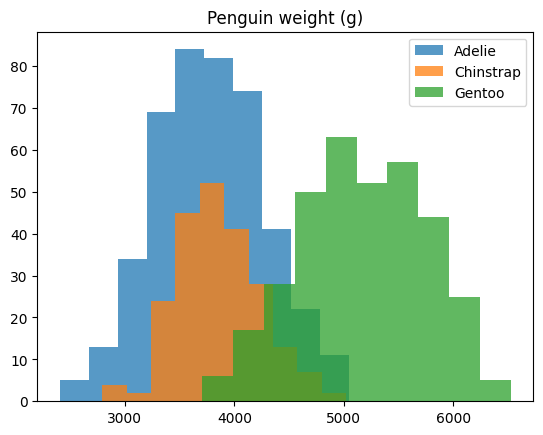

In [4]:
for specie in np.unique(data['espece']):
    plt.hist(data[data['espece'] == specie]['masse_g'], alpha = 0.75, label = specie)

plt.title("Penguin weight (g)")
plt.legend()

# Visible normal/gaussian distribution

Text(0.5, 1.0, 'Scatter plot of the penguins by beak length and weight')

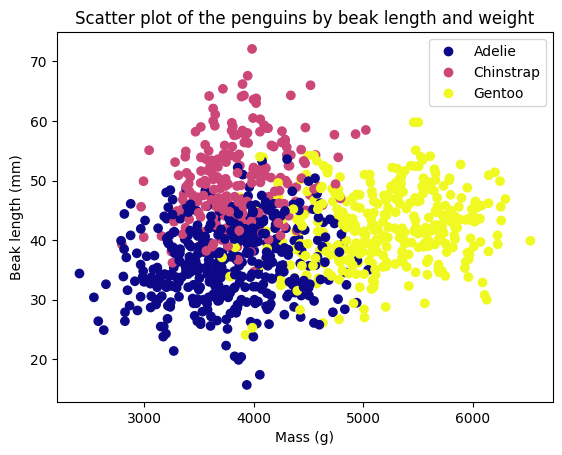

In [5]:
train_species0 = np.unique(train_species, return_inverse=True)[1]

dispersion = plt.scatter(data['masse_g'], data['longueur_bec_mm'], c = train_species0, cmap = 'plasma' )

plt.xlabel('Mass (g)')
plt.ylabel('Beak length (mm)')
plt.legend(handles = dispersion.legend_elements()[0], labels = ['Adelie', 'Chinstrap', 'Gentoo'])
plt.title("Scatter plot of the penguins by beak length and weight")

# The separation between the points seems to be homogeneous, a knn algorithm could be considered

In [6]:
def cov(x,y):
    return np.mean((x-np.mean(x))*(y-np.mean(y)))

def corr(x,y):
    return cov(x,y)/np.sqrt(cov(x,x)*cov(y,y))

In [7]:
def corr_mat(data):
    cols = data.columns
    n = len(cols)
    corr_mat = np.zeros((n, n))
    for i in range(n):
        for j in range(n):
            corr_mat[i][j] = corr(data[cols[i]],data[cols[j]])
    
    return pd.DataFrame(corr_mat, index=cols, columns=cols)

In [8]:
measures = ['longueur_bec_mm', 'epaisseur_bec_mm', 'longueur_nageoire_mm','masse_g']

train_measures = data[measures]
train_measures.head()

,longueur_bec_mm,epaisseur_bec_mm,longueur_nageoire_mm,masse_g
Id,,,,
0,47.4,15.7,256,3750
1,33.3,21.4,247,4682
2,47.4,10.9,262,4192
3,36.7,6.7,252,4798
4,34.6,16.1,175,3418


In [9]:
corr_mat(train_measures)

,longueur_bec_mm,epaisseur_bec_mm,longueur_nageoire_mm,masse_g
longueur_bec_mm,1.000000,0.085246,0.040767,0.151383
epaisseur_bec_mm,0.085246,1.000000,-0.322910,-0.592272
longueur_nageoire_mm,0.040767,-0.322910,1.000000,0.397937
masse_g,0.151383,-0.592272,0.397937,1.000000


([<matplotlib.axis.YTick at 0x7e83e8793920>,
 [Text(0, 0, 'longueur_bec_mm'),
  Text(0, 1, 'epaisseur_bec_mm'),
  Text(0, 2, 'longueur_nageoire_mm'),
  Text(0, 3, 'masse_g')])

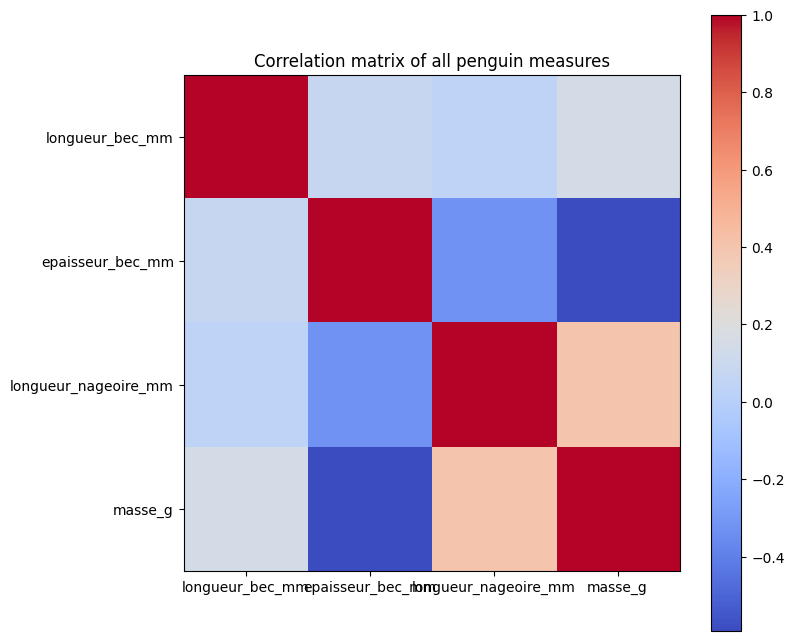

In [10]:
plt.figure(figsize=(8,8))
_ = plt.imshow(corr_mat(train_measures), cmap = 'coolwarm')
_ = plt.colorbar()

plt.title("Correlation matrix of all penguin measures")
plt.xticks(range(4), measures)
plt.yticks(range(4), measures)

Text(0.5, 1.0, 'Correlation matrix of all penguin measures')

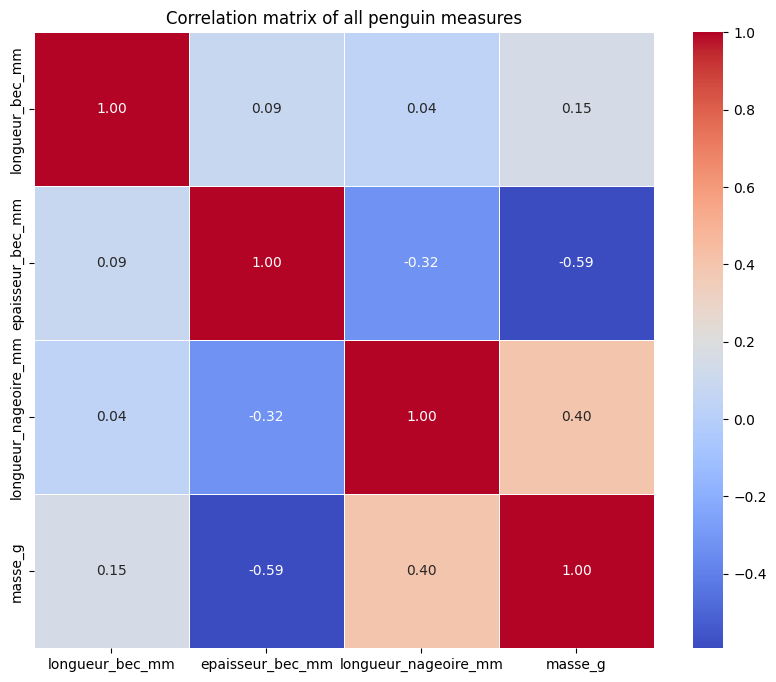

In [11]:
corr_mat2 = train_measures.corr()

plt.figure(figsize=(10,8))
heatmap(corr_mat2, annot = True, cmap="coolwarm", fmt=".2f", linewidths= 0.5)
plt.title("Correlation matrix of all penguin measures")

**Class 2 (Naive Bayes)**



In [12]:
def discrete_naive_bayes(x, X):
    """Predicts the species of a penguin using the training dataset data, and the values in x taken by the discrete variables in X."""
    
    proba = data['espece'].value_counts(normalize = True).sort_index(ascending=True)
    # P(Species)
    
    for i in range(len(X)): # iterates the chosen discrete variables
        p_xSpecies = pd.crosstab(data['espece'], data[X[i]], normalize = 'index')
        # P(X|Species)
        proba = proba * p_xSpecies[x[i]]

    return proba.idxmax()

In [13]:
def prediction_discrete_bayes(test_data, X):
    """Predicts the species of each penguin in data_test using the discrete variables in X."""

    x = test_data[X].to_numpy()
    
    return [discrete_naive_bayes(x[i], X) for i in range(len(test_data))]

In [14]:
def confusion_matrix(predictions, real_classes):

    pred = np.unique(predictions, return_inverse=True)[1]
    real = np.unique(real_classes, return_inverse=True)[1]
    
    length = len(np.unique(pred))
    res_mat = np.zeros((length, length))
    for i in range(len(pred)):
        res_mat[real[i]][pred[i]] += 1
        
    return res_mat

In [15]:
disc_measures = ['ile_origine', 'sexe']

pred_discrete_train = prediction_discrete_bayes(data, disc_measures)
pred_discrete_prev = prediction_discrete_bayes(prev_data, disc_measures)
pred_discrete_prev[:10]

['Adelie',
 'Adelie',
 'Adelie',
 'Adelie',
 'Chinstrap',
 'Gentoo',
 'Chinstrap',
 'Gentoo',
 'Chinstrap',
 'Gentoo']

In [16]:
def bias(predictions, real_classes):
    
    pred = np.unique(predictions, return_inverse=True)[1]
    real = np.unique(real_classes, return_inverse=True)[1]

    return np.mean(pred != real)

In [17]:
bias(pred_discrete_train, train_species)

np.float64(0.361)

([<matplotlib.axis.YTick at 0x7e83eacf9400>,
 [Text(0, 0, 'Real Adélie'),
  Text(0, 1, 'Real Chinstrap'),
  Text(0, 2, 'Real Gentoo')])

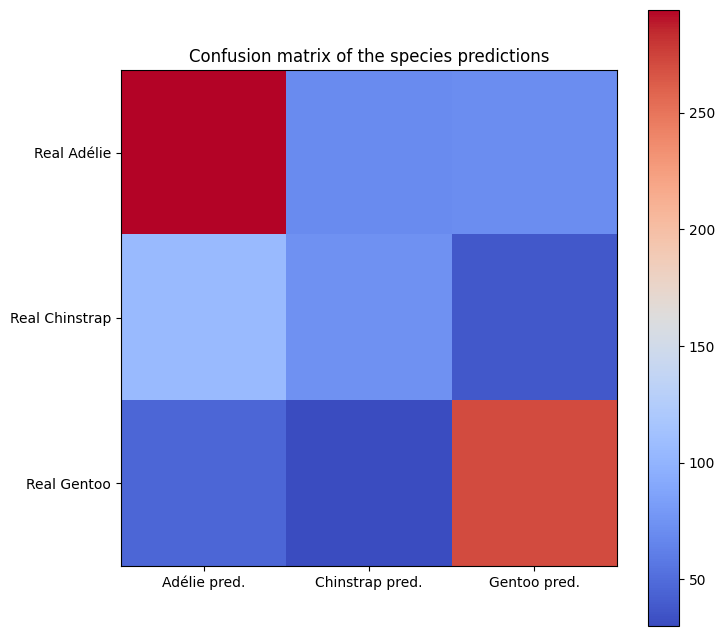

In [18]:
m_confus_discrete = confusion_matrix(pred_discrete_train, train_species)

plt.figure(figsize = (8,8))
_ = plt.imshow(m_confus_discrete, cmap = 'coolwarm')
_ = plt.colorbar()
_ = plt.title("Confusion matrix of the species predictions")

plt.xticks(range(3), ['Adélie pred.', 'Chinstrap pred.', 'Gentoo pred.'])
plt.yticks(range(3), ['Real Adélie', 'Real Chinstrap', 'Real Gentoo'])

# Our predictions for Adelie and Gentoo penguins were very accurate, but alot less for the Chinstrap penguins.
# This was expected, as unlike Adelie and Gentoo penguins, Chinstraps do not have an island where they represent a large majority.

**Continuous version**

In [19]:
def gaussian_param(data, X):
    """Returns the parameters of the probability density function for each continuous variable in X."""
    
    res_l = []
    species = np.unique(data['espece'])

    for rand_var in X:
        mu = {speciesx: data[data["espece"]==speciesx][rand_var].mean() for speciesx in species}
        sigma = {speciesx: data[data["espece"]==speciesx][rand_var].var() for speciesx in species}
        res_l.append((mu, sigma))
    
    return res_l

In [20]:
def gaussian(x, mu, sigma2):
    return (1/np.sqrt(2*np.pi*sigma2)) * np.exp(-(x-mu)**2/(2*sigma2))

In [21]:
def continuous_naive_bayes(x, X):
    """Predicts the species of a penguin using the training dataset data, and the values in x taken by the continuous variables in X."""
    
    species = np.unique(data['espece'])
    param_X = gaussian_param(data, X)
    
    proba = data['espece'].value_counts(normalize = True).sort_index(ascending=True).to_numpy()
    # P(Species)
    
    for k in range(3): # Adelie: k = 0, Chinstrap: k = 1, Gentoo: k = 2
        for i in range(len(X)): # iterates the chosen continuous variables
            mu, sigma = param_X[i][0], param_X[i][1]
            proba[k] = proba[k] * gaussian(x[i], mu[species[k]], sigma[species[k]])
        
    ind = np.argmax(proba)
    
    return species[ind]

In [22]:
def prediction_continuous_bayes(data_test, X):
    """Predicts the species of each penguin in data_test using the continuous variables in X"""

    x = data_test[X].to_numpy()

    return [continuous_naive_bayes(x[i], X) for i in range(len(data_test))]


In [23]:
pred_continuous_train = prediction_continuous_bayes(data, measures)
pred_continuous_prev = prediction_continuous_bayes(prev_data, measures)

([<matplotlib.axis.YTick at 0x7e83ead24b00>,
 [Text(0, 0, 'Real Adélie'),
  Text(0, 1, 'Real Chinstrap'),
  Text(0, 2, 'Real Gentoo')])

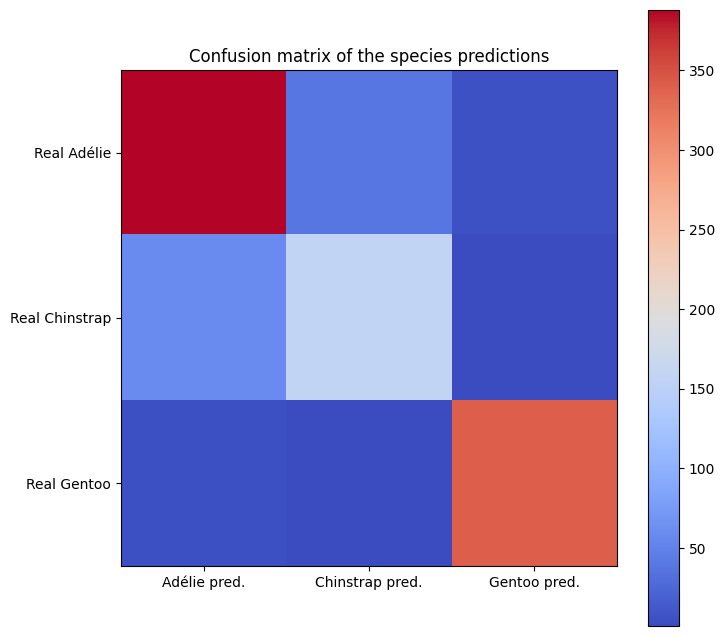

In [24]:
m_confus_continuous = confusion_matrix(pred_continuous_train, train_species)

plt.figure(figsize = (8,8))
_ = plt.imshow(m_confus_continuous, cmap = 'coolwarm')
_ = plt.colorbar()
_ = plt.title("Confusion matrix of the species predictions")

plt.xticks(range(3), ['Adélie pred.', 'Chinstrap pred.', 'Gentoo pred.'])
plt.yticks(range(3), ['Real Adélie', 'Real Chinstrap', 'Real Gentoo'])

# Alot more accurate than the discrete version

In [25]:
bias(pred_continuous_train, train_species)

np.float64(0.113)

**Discrete AND continuous version**

In [26]:
def naive_bayes(x_disc, X_disc, x_cont, X_cont):
    """Predicts the species of a penguin using the training dataset data, and the values in x_disc (resp. x_cont) taken by the
    discrete variables (resp. continuous in X_cont)"""

    species = np.unique(data['espece'])
    param_X = gaussian_param(data, X_cont)
    
    proba = data['espece'].value_counts(normalize = True).sort_index(ascending=True)
    # P(Species)

    for i in range(len(X_disc)): # iterates the chosen discrete variables
        p_xSespece = pd.crosstab(data['espece'], data[X_disc[i]], normalize = 'index')
        # P(X|Species)
        proba = proba * p_xSespece[x_disc[i]]

    proba = proba.to_numpy()
    
    for k in range(3): # Adelie: k = 0, Chinstrap: k = 1, Gentoo: k = 2
        for i in range(len(X_cont)): # iterates the chosen discrete variables
            mu, sigma = param_X[i][0], param_X[i][1]
            proba[k] = proba[k] * gaussian(x_cont[i], mu[species[k]], sigma[species[k]])
        
    ind = np.argmax(proba)

    return species[ind]

In [27]:
def prediction_bayes(data_test, X_disc, X_cont):
    """Predicts the species of each penguin in data_test using the discrete variables in X_disc and continuous variables in X_cont."""

    x_disc = data_test[X_disc].to_numpy()
    x_cont = data_test[X_cont].to_numpy()

    return [naive_bayes(x_disc[i], X_disc, x_cont[i], X_cont) for i in range(len(data_test))]

In [28]:
pred_bayes_train = prediction_bayes(data, disc_measures, measures)
pred_bayes_prev = prediction_bayes(prev_data, disc_measures, measures)

In [29]:
bias(pred_bayes_train, train_species)
# Using both types of variables reduces the bias even more.

np.float64(0.1)

([<matplotlib.axis.YTick at 0x7e83e6efc440>,
 [Text(0, 0, 'Real Adélie'),
  Text(0, 1, 'Real Chinstrap'),
  Text(0, 2, 'Real Gentoo')])

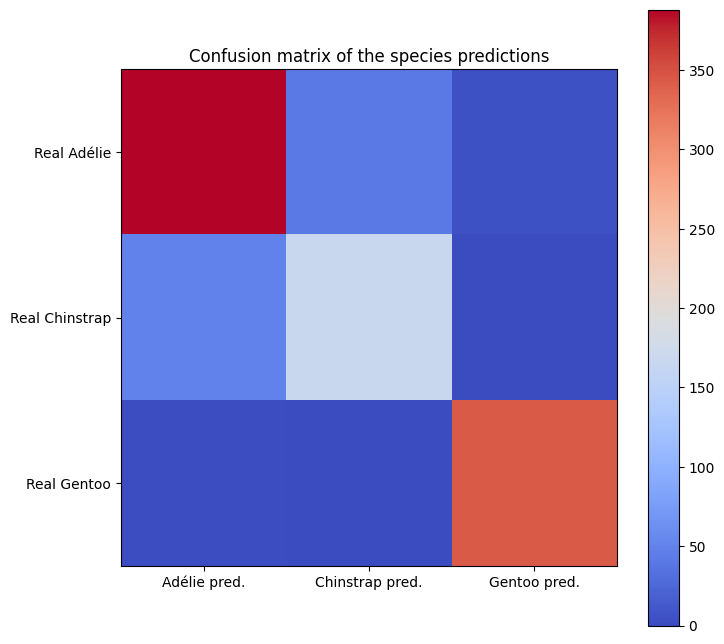

In [30]:
m_confus_bayes = confusion_matrix(pred_bayes_train, train_species)

plt.figure(figsize = (8,8))
_ = plt.imshow(m_confus_bayes, cmap = 'coolwarm')
_ = plt.colorbar()
_ = plt.title("Confusion matrix of the species predictions")

plt.xticks(range(3), ['Adélie pred.', 'Chinstrap pred.', 'Gentoo pred.'])
plt.yticks(range(3), ['Real Adélie', 'Real Chinstrap', 'Real Gentoo'])

**Class 3 (k-nearest-neighbors)**

In [31]:
def majority_class(labels):
    
    classes, counts = np.unique(labels,return_counts=True)
    ind = np.argmax(counts)
    
    return classes[ind]

In [32]:
def knn(k, data_train, x, X):
    """Predicts the species of a penguin using the training dataset data_train and the values in x taken by the continuous variables in X."""

    species = data_train['espece'].to_numpy()
    x_train = data_train[X].to_numpy()
    
    dist = np.sum((x_train - x)**2, axis = 1) 
    ind = np.argsort(dist)
    species_knn = species[ind][:k]
    
    return majority_class(species_knn)

In [33]:
def predictions_knn(k, train_data, test_data, X):
    """Predicts the species of each penguin in data_test using data_train and the continuous variables in X."""
    
    x = test_data[X].to_numpy()

    return [knn(k, train_data, x[i], X) for i in range(len(test_data))]

Text(0.5, 1.0, 'Bias of the algorithm corresponding to the chosen k')

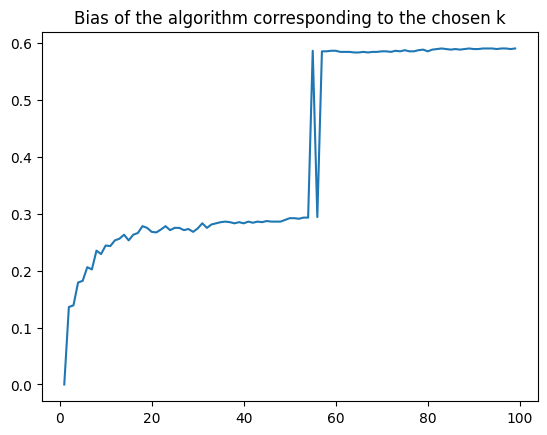

In [34]:
X = [i for i in range(1, 100)]
Y = [bias(predictions_knn(k, data, data, measures), train_species) for k in X]
    
plt.plot(X, Y)
plt.title("Bias of the algorithm corresponding to the chosen k")

# A smaller k leads to overfitting while a bigger k leads to underfitting.

In [35]:
pred_knn_train5 = predictions_knn(5, data, data, measures)
pred_knn_prev5 = predictions_knn(5, data, prev_data, measures)

bias(pred_knn_train5, train_species)

# First attempt with k = 5 has a considerably high bias both in the training dataset and the testing
# dataset. The choice for k can be refined later while at the same time not going too into underfitting or
# overfitting.

np.float64(0.182)

([<matplotlib.axis.YTick at 0x7e83e6e3cb30>,
 [Text(0, 0, 'Real Adélie'),
  Text(0, 1, 'Real Chinstrap'),
  Text(0, 2, 'Real Gentoo')])

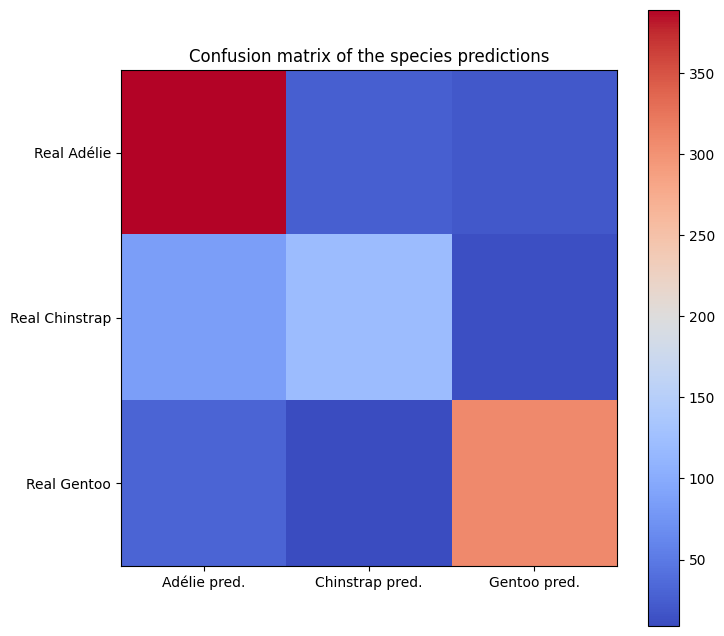

In [36]:
m_confus_knn = confusion_matrix(pred_knn_train5, train_species)

plt.figure(figsize = (8,8))
_ = plt.imshow(m_confus_knn, cmap = 'coolwarm')
_ = plt.colorbar()
_ = plt.title("Confusion matrix of the species predictions")

plt.xticks(range(3), ['Adélie pred.', 'Chinstrap pred.', 'Gentoo pred.'])
plt.yticks(range(3), ['Real Adélie', 'Real Chinstrap', 'Real Gentoo'])

**Class 4 (Hyper-parameters)**

In [37]:
def knn_cv(data, k_neighbors, X, k_folds = 5):
    """Applies the knn algorithm using cross-valdation and returns the average 
    bias of all iterations."""

    biases = []
    
    for i in range(k_folds):

        lower_bound, upper_bound = (1000//k_folds)*i, (1000//k_folds)*(i+1)
        train_data = pd.concat([data.iloc[:lower_bound], data.iloc[upper_bound:]]) 
        test_data = data.iloc[lower_bound:upper_bound]
        
        pred = predictions_knn(k_neighbors, train_data, test_data, X)
        real_classes = test_data['espece']

        biases.append(bias(pred, real_classes))
    
    return np.mean(biases)

In [38]:
avg_biases = [knn_cv(data, k, measures) for k in range(1,31)]

np.argmin(avg_biases), np.min(avg_biases)
# Using cross validation, k = 3 seems to be the wisest choice for the knn algorithm

(np.int64(2), np.float64(0.28500000000000003))

Text(0.5, 1.0, 'Bias of the algorithm corresponding to the chosen k using CV')

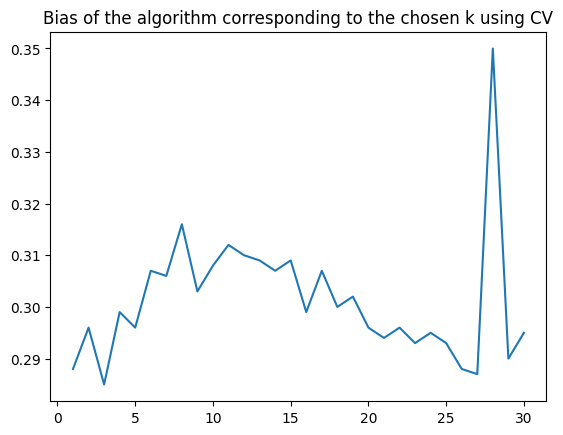

In [39]:
X = [i for i in range(1, 31)]
Y = [knn_cv(data, k, measures) for k in X]
    
plt.plot(X, Y)
plt.title("Bias of the algorithm corresponding to the chosen k using CV")

In [40]:
pred_knn_train3 = predictions_knn(3, data, data, measures)
pred_knn_prev3 = predictions_knn(3, data, prev_data, measures)

bias(pred_knn_train3, train_species)

np.float64(0.139)

([<matplotlib.axis.YTick at 0x7e83e6e3e1e0>,
 [Text(0, 0, 'Real Adélie'),
  Text(0, 1, 'Real Chinstrap'),
  Text(0, 2, 'Real Gentoo')])

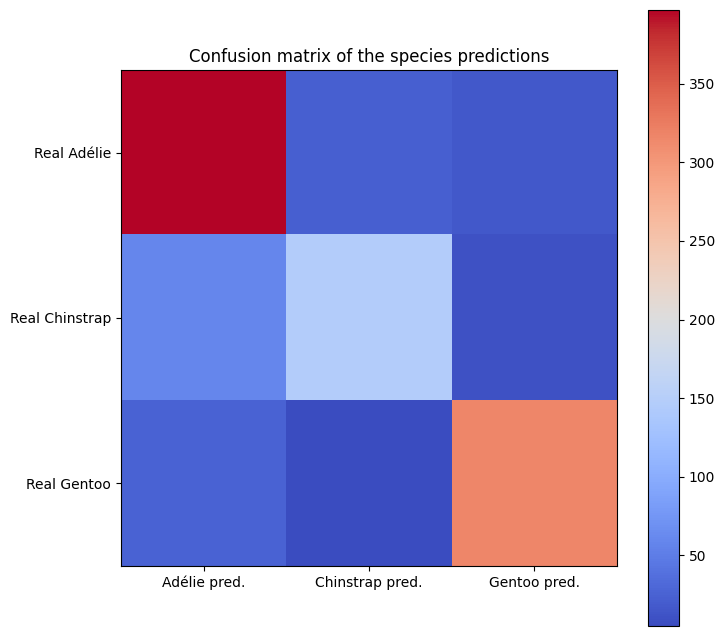

In [41]:
m_confus_knn = confusion_matrix(pred_knn_train3, train_species)

plt.figure(figsize = (8,8))
_ = plt.imshow(m_confus_knn, cmap = 'coolwarm')
_ = plt.colorbar()
_ = plt.title("Confusion matrix of the species predictions")

plt.xticks(range(3), ['Adélie pred.', 'Chinstrap pred.', 'Gentoo pred.'])
plt.yticks(range(3), ['Real Adélie', 'Real Chinstrap', 'Real Gentoo'])

**Class 5 (Decision Trees)**

In [42]:
def gini(y):
    classes, counts = np.unique(y, return_counts=True)
    p = counts / len(y)
    return 1 - np.sum(p**2)

In [43]:
def best_split(X, y, types_variables, n_min_leaves=1):
    
    n_samples, n_features = X.shape
    best_feature = None
    best_value = None
    best_type = None
    best_score = float('inf')

    for j in range(n_features):
        values = np.unique(X[:,j])

        if types_variables[j] == 'C':
            
            for t in values:
                left = (X[:, j] <= t)
                right = (X[:, j] > t)

                if left.sum() < n_min_leaves or right.sum() < n_min_leaves:
                    continue
                score = (left.sum()*gini(y[left])+right.sum()*gini(y[right])) / n_samples

                if score < best_score:
                    best_score = score
                    best_feature = j
                    best_value = t
                    best_type = 'C'

        else:
            for c in values:

                left = (X[:, j] == c)
                right = (X[:, j] != c)

               
                if (left.sum()<n_min_leaves)or(right.sum()<n_min_leaves):
                    continue
                score = (left.sum()*gini(y[left])+right.sum()*gini(y[right])) / n_samples
                
                if score < best_score:
                    best_score = score
                    best_feature = j
                    best_value =c
                    best_type = 'D'
                    
    return best_feature, best_value, best_type

In [44]:
def build_tree(X, y, types_variables, depth=0, max_depth=5, n_min_split=2):
    
    if len(y) < n_min_split or depth >= max_depth or len(np.unique(y)) == 1:
        return {'label': majority_class(y)}
    
    feature, value, split_type = best_split(X, y, types_variables)

    if feature is None:
        return {'label': majority_class(y)}
    
    if split_type == 'C':
        left = (X[:, feature] <= value)
        right = (X[:, feature] > value)
    else:
        left = (X[:, feature] == value)
        right = (X[:, feature] != value)
    
    left_tree = build_tree(X[left], y[left], types_variables, depth + 1, max_depth, n_min_split)

    right_tree = build_tree(X[right], y[right], types_variables, depth + 1, max_depth, n_min_split)

    return {
        'feature': feature,
        'value': value,
        'type': split_type,
        'left': left_tree,
        'right': right_tree
    }

In [45]:
def predict(tree, x):
    if 'label' in tree:
        return tree['label']
    
    if tree['type'] == 'C':
        if x[tree['feature']] <= tree['value']:
            return predict(tree['left'], x)
        else:
            return predict(tree['right'], x)
    
    else:
        if x[tree['feature']] == tree['value']:
            return predict(tree['left'], x)
        else:
            return predict(tree['right'], x)

In [46]:
var_types = ['D','C','C','C','C','D']
decision_tree = build_tree(np.array(data.iloc[:,1:]), train_species, var_types)

In [47]:
def pred_decision_tree(test_data, tree):

    test_info = np.array(test_data.iloc[:,1:])
    pred_tree = []
    for penguin in test_info:
        pred_tree.append(predict(tree, penguin))
    return pred_tree

In [48]:
pred_tree_train = pred_decision_tree(data, decision_tree)
pred_tree_prev = pred_decision_tree(prev_data, decision_tree)

bias(pred_tree_train, train_species)
# Capping the tree depth at 5 allows a very low bias both in the training data (9%) 
# and in the test data (6.1%)

np.float64(0.09)

([<matplotlib.axis.YTick at 0x7e83e690cb00>,
 [Text(0, 0, 'Real Adélie'),
  Text(0, 1, 'Real Chinstrap'),
  Text(0, 2, 'Real Gentoo')])

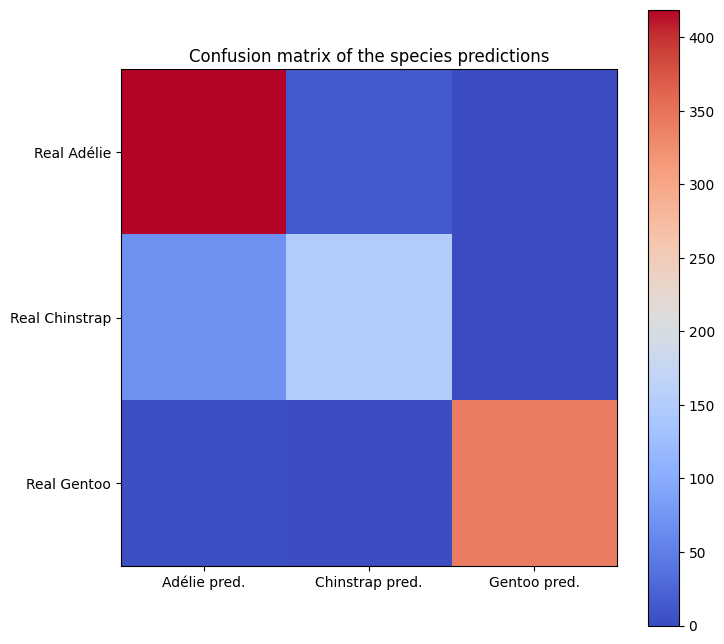

In [49]:
m_confus_tree = confusion_matrix(pred_tree_train, train_species)

plt.figure(figsize = (8,8))
_ = plt.imshow(m_confus_tree, cmap = 'coolwarm')
_ = plt.colorbar()
_ = plt.title("Confusion matrix of the species predictions")

plt.xticks(range(3), ['Adélie pred.', 'Chinstrap pred.', 'Gentoo pred.'])
plt.yticks(range(3), ['Real Adélie', 'Real Chinstrap', 'Real Gentoo'])

**Class 6 (Random forest)**

In [50]:
def create_random_forest(X, y, types_variables, n_trees=15, max_depth=7):
    
    forest = []
    n_samples = X.shape[0]
    
    for i in range(n_trees):
        #Bagging
        ind = np.random.choice(n_samples, size=n_samples, replace=True)
        X_sample = X[ind]
        y_sample = y[ind]
        
        tree = build_tree(X_sample, y_sample, types_variables, depth=0, max_depth=max_depth)
        forest.append(tree)
        
    return forest

In [51]:
def predict_random_forest(test_data, forest):

    test_info = np.array(test_data.iloc[:, 1:])
    predictions = []
    
    for penguin in test_info:
        pred = [predict(tree, penguin) for tree in forest]
        pred_final = majority_class(pred) # Voting
        predictions.append(pred_final)
        
    return predictions

In [52]:
random_forest = create_random_forest(np.array(data.iloc[:, 1:]), train_species, var_types)

In [53]:
pred_randfor_train = predict_random_forest(data, random_forest)
pred_randfor_prev = predict_random_forest(prev_data, random_forest)

bias(pred_randfor_train, train_species)

# Tuning the max tree depth at 7 allows a very low bias both in the training data (3%) 
# and in the test data (5.1%)

np.float64(0.046)

([<matplotlib.axis.YTick at 0x7e83e67b8230>,
 [Text(0, 0, 'Real Adélie'),
  Text(0, 1, 'Real Chinstrap'),
  Text(0, 2, 'Real Gentoo')])

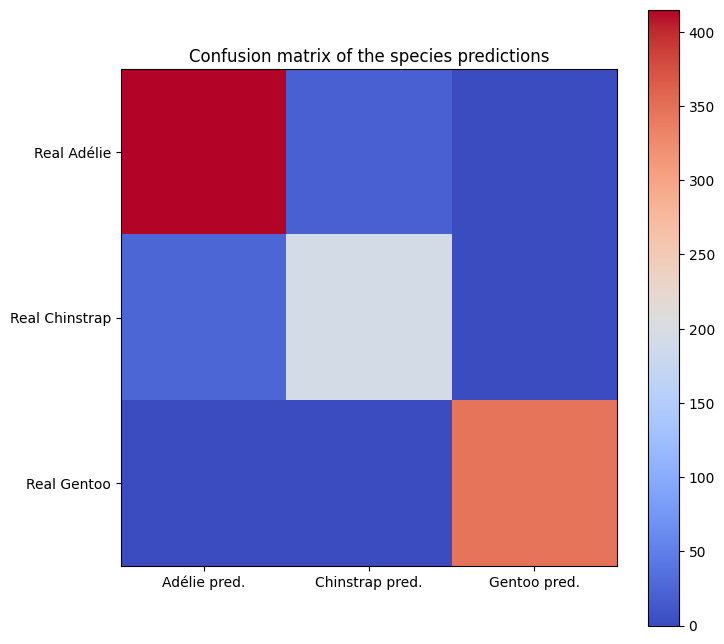

In [54]:
m_confus_forest = confusion_matrix(pred_randfor_train, train_species)

plt.figure(figsize = (8,8))
_ = plt.imshow(m_confus_forest, cmap = 'coolwarm')
_ = plt.colorbar()
_ = plt.title("Confusion matrix of the species predictions")

plt.xticks(range(3), ['Adélie pred.', 'Chinstrap pred.', 'Gentoo pred.'])
plt.yticks(range(3), ['Real Adélie', 'Real Chinstrap', 'Real Gentoo'])

In [55]:
submission = pd.DataFrame({
    "Id": prev_data["Id"],
    "espece": pred_randfor_prev
})

submission.to_csv("submission.csv", index=False)